# Multimodal Product Classifier: Text + Image

**Problem:** A product catalog has both an image and a short title for each item. The question I actually care about is when adding the image *helps* category prediction vs being expensive noise.

**Data:** real catalog listings from the Myntra-based "Fashion Product Images (Small)" dataset (Param Aggarwal, Kaggle), loaded from the Hugging Face copy `ashraq/fashion-product-images-small`. Each item has a product photo (60x80 thumbnail) and a display name like "Titan Women Silver Watch". I read the first 10,000-row parquet row group and sample 100 items from each of 6 categories: shirts, shoes, bags, watches, jewellery and eyewear (600 items).

The display names usually contain the category word, so text-only on raw titles is close to perfect. To make the question interesting I build a **masked-title** version where the category words are replaced by "item". What's left is brand, gender, colour and style words, which still carry some signal (Titan mostly sells watches) but much less.

**Approach:** Four baselines on the *masked-title* task.
1. TF-IDF + logistic regression on masked titles.
2. CLIP text-only embeddings on masked titles.
3. CLIP image-only embeddings.
4. Concat fusion (CLIP text + image).

Everything runs on CPU; CLIP ViT-B/32 is small enough.

**What this isn't:** a full benchmark. With 150 test items, each accuracy number has an uncertainty of a few points. Caveats are at the bottom.

In [1]:
# !pip install transformers Pillow scikit-learn -q

In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import torch
from transformers import CLIPProcessor, CLIPModel
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from tqdm import tqdm

np.random.seed(42)
torch.manual_seed(42)

torch.set_num_threads(2)
device = torch.device("cpu")
print(f"Device: {device}")

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

Device: cpu


In [3]:
import io
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem

fs = HfFileSystem()
pf = pq.ParquetFile(fs.open("datasets/ashraq/fashion-product-images-small/data/train-00000-of-00002-6cff4c59f91661c3.parquet"))
raw = pf.read_row_group(0, columns=["id", "subCategory", "articleType", "productDisplayName", "image"]).to_pandas()

def category(r):
    if r["articleType"] == "Shirts": return "shirts"
    return {"Shoes": "shoes", "Bags": "bags", "Watches": "watches",
            "Jewellery": "jewellery", "Eyewear": "eyewear"}.get(r["subCategory"])
raw["category"] = raw.apply(category, axis=1)
df = (raw.dropna(subset=["category", "productDisplayName"])
         .groupby("category", group_keys=False).apply(lambda g: g.sample(100, random_state=42))
         .reset_index(drop=True))
df["title"] = df["productDisplayName"]
df["image_bytes"] = df["image"].apply(lambda d: d["bytes"])
print(f"Loaded {len(df)} products from {len(raw)} rows")

# Masked title: replace the words that name the category (and common variants) with "item".
CATEGORY_WORDS = r"shirts?|shoes?|sneakers?|loafers?|boots?|heels|flats|bags?|handbags?|backpacks?|clutch(es)?|totes?|" \
                 r"wallets?|messenger|laptop|watch(es)?|chronograph|jewell?e?ry|earrings?|necklaces?|pendants?|rings?|" \
                 r"bracelets?|bangles?|sunglasses|eyewear|aviators?|wayfarers?|frames?"
def mask_title(title: str) -> str:
    return re.sub(rf"\b({CATEGORY_WORDS})\b", "item", title, flags=re.IGNORECASE)

df["title_masked"] = df["title"].astype(str).apply(mask_title)
df[["category", "title", "title_masked"]].head(6)

Loaded 600 products from 10000 rows


,category,title,title_masked
0,bags,Mod-acc Women Purple Handbag,Mod-acc Women Purple item
1,bags,Fastrack Men Navy Blue Backpack,Fastrack Men Navy Blue item
2,bags,Murcia Women Turquoise Blue Handbag,Murcia Women Turquoise Blue item
3,bags,Hidekraft Women Leather Maroon Handbags,Hidekraft Women Leather Maroon item
4,bags,Rocia Women Maroon Handbag,Rocia Women Maroon item
5,bags,Wildcraft Unisex Grey Gear for Life Backpack,Wildcraft Unisex Grey Gear for Life item


## EDA — class balance, and "is text alone too easy?" sanity check

Two views:
1. Category distribution (small dataset, roughly balanced).
2. Quick TF-IDF accuracy on **raw** vs **masked** titles. We expect raw to be near-100% because the category word is in the title. That confirms the masking is doing something useful before we spend CLIP cycles.

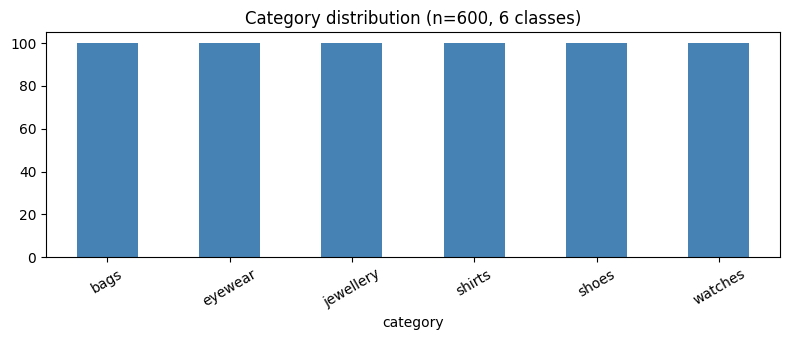

TF-IDF on RAW titles    : 0.980  (sanity — category word is in title)
TF-IDF on MASKED titles : 0.853  (the real task we'll evaluate)


In [4]:
cat_col, title_col, img_col = "category", "title", "image_bytes"

fig, ax = plt.subplots(figsize=(8, 3.5))
df[cat_col].value_counts().plot(kind="bar", ax=ax, color="steelblue")
ax.set_title(f"Category distribution (n={len(df)}, {df[cat_col].nunique()} classes)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(ARTIFACTS / "category_distribution.png", dpi=120)
plt.show()

# Sanity check: raw titles trivially solve the task; masked titles don't.
le_quick = LabelEncoder()
y_quick = le_quick.fit_transform(df[cat_col])
def quick_tfidf_acc(texts):
    Xtr, Xte, ytr, yte = train_test_split(texts, y_quick, test_size=0.25, stratify=y_quick, random_state=42)
    v = TfidfVectorizer(max_features=2000)
    Xtr_v = v.fit_transform(Xtr); Xte_v = v.transform(Xte)
    clf = LogisticRegression(max_iter=1000).fit(Xtr_v, ytr)
    return accuracy_score(yte, clf.predict(Xte_v))

print(f"TF-IDF on RAW titles    : {quick_tfidf_acc(df['title']):.3f}  (sanity — category word is in title)")
print(f"TF-IDF on MASKED titles : {quick_tfidf_acc(df['title_masked']):.3f}  (the real task we'll evaluate)")

## CLIP embeddings (text on masked titles, image on the product photos)

In [5]:
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_proc  = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
clip_model.eval()

@torch.no_grad()
def get_text_embs(texts, batch=32):
    out = []
    for i in range(0, len(texts), batch):
        chunk = [str(t)[:200] for t in texts[i:i + batch]]
        inputs = clip_proc(text=chunk, return_tensors="pt", padding=True, truncation=True).to(device)
        out.append(clip_model.get_text_features(**inputs).cpu().numpy())
    return np.concatenate(out, axis=0)

@torch.no_grad()
def get_image_embs(paths, batch=16):
    out = []
    for i in range(0, len(paths), batch):
        imgs = [Image.open(io.BytesIO(b)).convert("RGB") for b in paths[i:i + batch]]
        inputs = clip_proc(images=imgs, return_tensors="pt").to(device)
        out.append(clip_model.get_image_features(**inputs).cpu().numpy())
    return np.concatenate(out, axis=0)

# Embed all 600 products.
text_embs  = get_text_embs(df["title_masked"].tolist())
image_embs = get_image_embs(df[img_col].tolist())
print(f"text embs: {text_embs.shape}  |  image embs: {image_embs.shape}")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

text embs: (600, 512)  |  image embs: (600, 512)


## Four classifiers, same train/test split

To keep the comparison fair, every model uses **the same** split (same `random_state`, same stratification).

In [6]:
le = LabelEncoder()
y = le.fit_transform(df[cat_col])

# TF-IDF features
tfidf = TfidfVectorizer(max_features=2000, ngram_range=(1, 2))
X_tfidf = tfidf.fit_transform(df["title_masked"].astype(str)).toarray()

X_text  = text_embs
X_image = image_embs
X_multi = np.concatenate([text_embs, image_embs], axis=1)

# Single train/test split shared across all four models — reduces variance from resampling.
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.25, stratify=y, random_state=42)
y_tr, y_te = y[idx_tr], y[idx_te]

def eval_features(X, label):
    clf = LogisticRegression(max_iter=2000, C=1.0, random_state=42)
    clf.fit(X[idx_tr], y_tr)
    pred = clf.predict(X[idx_te])
    acc = accuracy_score(y_te, pred)
    return acc, pred, clf

acc_tfidf, pred_tfidf, _   = eval_features(X_tfidf, "TF-IDF + LR")
acc_text,  pred_text,  clf_text  = eval_features(X_text,  "CLIP text")
acc_image, pred_image, clf_image = eval_features(X_image, "CLIP image")
acc_multi, pred_multi, _   = eval_features(X_multi, "CLIP multi (concat)")

results = pd.DataFrame({
    "model": ["TF-IDF + LR (masked text)", "CLIP text (masked)", "CLIP image", "CLIP concat (text+image)"],
    "test_acc": [acc_tfidf, acc_text, acc_image, acc_multi],
    "n_test": [len(y_te)] * 4,
})
print(results.to_string(index=False))

                    model  test_acc  n_test
TF-IDF + LR (masked text)  0.860000     150
       CLIP text (masked)  0.853333     150
               CLIP image  1.000000     150
 CLIP concat (text+image)  0.993333     150


## Disagreement slice — does the image help when text alone is unsure?

Pick test items where the **text-only CLIP model** is least confident, and see whether the multimodal model gets them right at a higher rate than the text-only model does on the same subset.

In [7]:
probs_text = clf_text.predict_proba(X_text[idx_te])
top_p = probs_text.max(axis=1)

# Take the bottom-third of test items by text confidence ("text isn't sure")
k = max(1, len(idx_te) // 3)
unsure_order = np.argsort(top_p)[:k]
unsure_te_idx = idx_te[unsure_order]

acc_text_on_unsure  = accuracy_score(y[unsure_te_idx], pred_text[unsure_order])
acc_multi_on_unsure = accuracy_score(y[unsure_te_idx], pred_multi[unsure_order])
acc_image_on_unsure = accuracy_score(y[unsure_te_idx], pred_image[unsure_order])

print(f"Hard slice ({k} test items where text is least confident):")
print(f"  CLIP text  acc: {acc_text_on_unsure:.3f}")
print(f"  CLIP image acc: {acc_image_on_unsure:.3f}")
print(f"  CLIP multi acc: {acc_multi_on_unsure:.3f}")
print(f"  Delta multi - text on hard slice: {acc_multi_on_unsure - acc_text_on_unsure:+.3f}")

Hard slice (50 test items where text is least confident):
  CLIP text  acc: 0.600
  CLIP image acc: 1.000
  CLIP multi acc: 0.980
  Delta multi - text on hard slice: +0.380


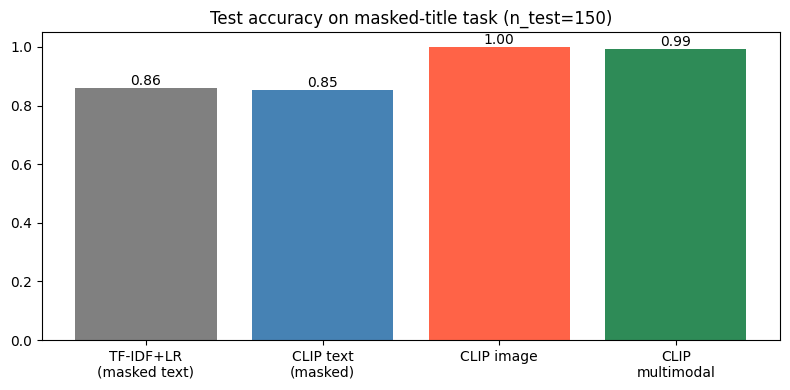


Multimodal classification report:
              precision    recall  f1-score   support

        bags       0.96      1.00      0.98        25
     eyewear       1.00      1.00      1.00        25
   jewellery       1.00      1.00      1.00        25
      shirts       1.00      1.00      1.00        25
       shoes       1.00      1.00      1.00        25
     watches       1.00      0.96      0.98        25

    accuracy                           0.99       150
   macro avg       0.99      0.99      0.99       150
weighted avg       0.99      0.99      0.99       150



In [8]:
labels = ["TF-IDF+LR\n(masked text)", "CLIP text\n(masked)", "CLIP image", "CLIP\nmultimodal"]
accs   = [acc_tfidf, acc_text, acc_image, acc_multi]

plt.figure(figsize=(8, 4))
bars = plt.bar(labels, accs, color=["gray", "steelblue", "tomato", "seagreen"])
for bar, a in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f"{a:.2f}", ha="center", fontsize=10)
plt.ylim(0, 1.05)
plt.title(f"Test accuracy on masked-title task (n_test={len(y_te)})")
plt.tight_layout()
plt.savefig(ARTIFACTS / "multimodal_ablation.png", dpi=120)
plt.show()

# print full classification report for the multimodal model
print("\nMultimodal classification report:")
print(classification_report(y_te, pred_multi, target_names=le.classes_, zero_division=0))

## Notes

- Real numbers above, computed in-cell. With 150 test items, one item is about 0.7 percentage points.
- Masked text is still fairly informative: TF-IDF gets 86% and CLIP text 85%, because brand and style words survive the mask (Fastrack and Wildcraft sell backpacks, Titan sells watches).
- The image alone gets 100%. These six categories look very different from each other (a shirt, a shoe and a pair of sunglasses), and the photos are clean catalog shots on white backgrounds, so this is an easy visual task for CLIP. Concat fusion lands at 99.3%, one mistake worse than image-only, which is within noise.
- The hard slice is where the question gets answered: on the 50 test items where the text model is least sure, text-only accuracy drops to 60%, and adding the image brings it to 98%. So the image is doing the work exactly where the title is ambiguous.
- To make this a fairer test I'd pick categories that look alike (shirts vs t-shirts vs kurtas, casual vs sports shoes), where the title might matter more than the photo, and use 5-fold CV so the deltas get error bars. After that, I'd replace concat-fusion with a small attention head that learns *when* to lean on the image vs the text.